# 🚗 Task 3: Car Price Prediction with Machine Learning

**Objective:** Build a regression model that predicts the selling price of a used car based on features  
such as brand, age, mileage, fuel type, and transmission.

**Tech Stack:** Python · pandas · scikit-learn · matplotlib · seaborn

---

### 📋 Table of Contents
1. Import Libraries & Load Data
2. Data Cleaning & Preprocessing
3. Feature Engineering
4. Exploratory Data Analysis
5. Encoding & Correlation Analysis
6. Model Training & Evaluation
7. Feature Importance
8. Best Model Declaration

---

## 1. 📦 Import Libraries & Load Dataset

In [1]:
# === Core Libraries ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# === scikit-learn Modules ===
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# === Configuration ===
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 120
plt.rcParams['font.family'] = 'sans-serif'

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# --- Load the Car Price dataset ---
df = pd.read_csv('datasets/car_data.csv')
print(f"📊 Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns")
df.head(10)

📊 Dataset loaded: 301 rows × 9 columns


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
5,vitara brezza,2018,9.25,9.83,2071,Diesel,Dealer,Manual,0
6,ciaz,2015,6.75,8.12,18796,Petrol,Dealer,Manual,0
7,s cross,2015,6.50,8.61,33429,Diesel,Dealer,Manual,0
8,ciaz,2016,8.75,8.89,20273,Diesel,Dealer,Manual,0
9,ciaz,2015,7.45,8.92,42367,Diesel,Dealer,Manual,0


## 2. 🧹 Data Cleaning & Preprocessing

### 2.1 Data Overview

In [3]:
print(f"📐 Shape: {df.shape}")
print(f"\n📋 Column Data Types:\n")
print(df.dtypes)

📐 Shape: (301, 9)

📋 Column Data Types:

Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64
dtype: object


In [4]:
# --- Null Value Check ---
print("\n🔎 Missing Values:\n")
print(df.isnull().sum())
print(f"\n{'─'*40}")
print(f"  Total Missing: {df.isnull().sum().sum()}")
print(f"{'─'*40}")


🔎 Missing Values:

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

────────────────────────────────────────
  Total Missing: 0
────────────────────────────────────────


> ✅ **No missing values detected.** The dataset is clean.

In [5]:
# --- Check for duplicates ---
dupes = df.duplicated().sum()
print(f"🔄 Duplicate rows: {dupes}")
if dupes > 0:
    df.drop_duplicates(inplace=True)
    print(f"✅ Removed {dupes} duplicates. New shape: {df.shape}")

🔄 Duplicate rows: 2
✅ Removed 2 duplicates. New shape: (299, 9)


In [6]:
# --- Check for inconsistent categorical values ---
print("\n📋 Unique values in categorical columns:\n")
for col in ['Fuel_Type', 'Seller_Type', 'Transmission']:
    unique_vals = df[col].unique()
    print(f"  {col}: {unique_vals}")


📋 Unique values in categorical columns:

  Fuel_Type: <StringArray>
['Petrol', 'Diesel', 'CNG']
Length: 3, dtype: str
  Seller_Type: <StringArray>
['Dealer', 'Individual']
Length: 2, dtype: str
  Transmission: <StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str


> ✅ Categorical values are consistent — no mixed-case or spelling issues detected.

In [7]:
# --- Descriptive Statistics ---
print("📊 Descriptive Statistics:\n")
df.describe().round(2)

📊 Descriptive Statistics:



,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,299.00,299.00,299.00,299.00,299.00
mean,2013.62,4.59,7.54,36916.75,0.04
std,2.90,4.98,8.57,39015.17,0.25
min,2003.00,0.10,0.32,500.00,0.00
25%,2012.00,0.85,1.20,15000.00,0.00
50%,2014.00,3.51,6.10,32000.00,0.00
75%,2016.00,6.00,9.84,48883.50,0.00
max,2018.00,35.00,92.60,500000.00,3.00


## 3. 🔧 Feature Engineering

In [8]:
# --- Calculate Car Age from Year column ---
current_year = 2024
df['Car_Age'] = current_year - df['Year']

print(f"📅 Car Age Range: {df['Car_Age'].min()} to {df['Car_Age'].max()} years")
print(f"📅 Average Car Age: {df['Car_Age'].mean():.1f} years")

📅 Car Age Range: 6 to 21 years
📅 Average Car Age: 10.4 years


In [9]:
# --- Extract Brand from Car Name ---
df['Brand'] = df['Car_Name'].apply(lambda x: x.split(' ')[0].lower().strip())

# Standardise common brand names
brand_mapping = {
    'toyot': 'toyota',
    'vw': 'volkswagen',
    'volk': 'volkswagen'
}
df['Brand'] = df['Brand'].replace(brand_mapping)

print(f"\n🏭 Unique Brands Found ({df['Brand'].nunique()}):\n")
brand_counts = df['Brand'].value_counts()
print(brand_counts)


🏭 Unique Brands Found (44):

Brand
city        26
bajaj       25
corolla     17
royal       17
honda       17
hero        15
verna       14
etios       11
fortuner    10
brio        10
ciaz         9
innova       9
i20          9
yamaha       8
tvs          8
grand        8
amaze        7
jazz         7
sx4          6
alto         6
eon          6
swift        5
ertiga       5
i10          5
ritz         4
wagon        4
dzire        4
ktm          4
activa       3
xcent        3
creta        3
elantra      2
vitara       1
s            1
ignis        1
800          1
baleno       1
omni         1
camry        1
land         1
um           1
hyosung      1
mahindra     1
suzuki       1
Name: count, dtype: int64


> **Feature Engineering Summary:**
> - Created `Car_Age` = Current Year − Manufacturing Year (more meaningful than raw year)
> - Extracted `Brand` from the full car name for brand-level analysis
> - Cleaned brand names for consistency

## 4. 📊 Exploratory Data Analysis

### 4.1 Distribution of Selling Prices

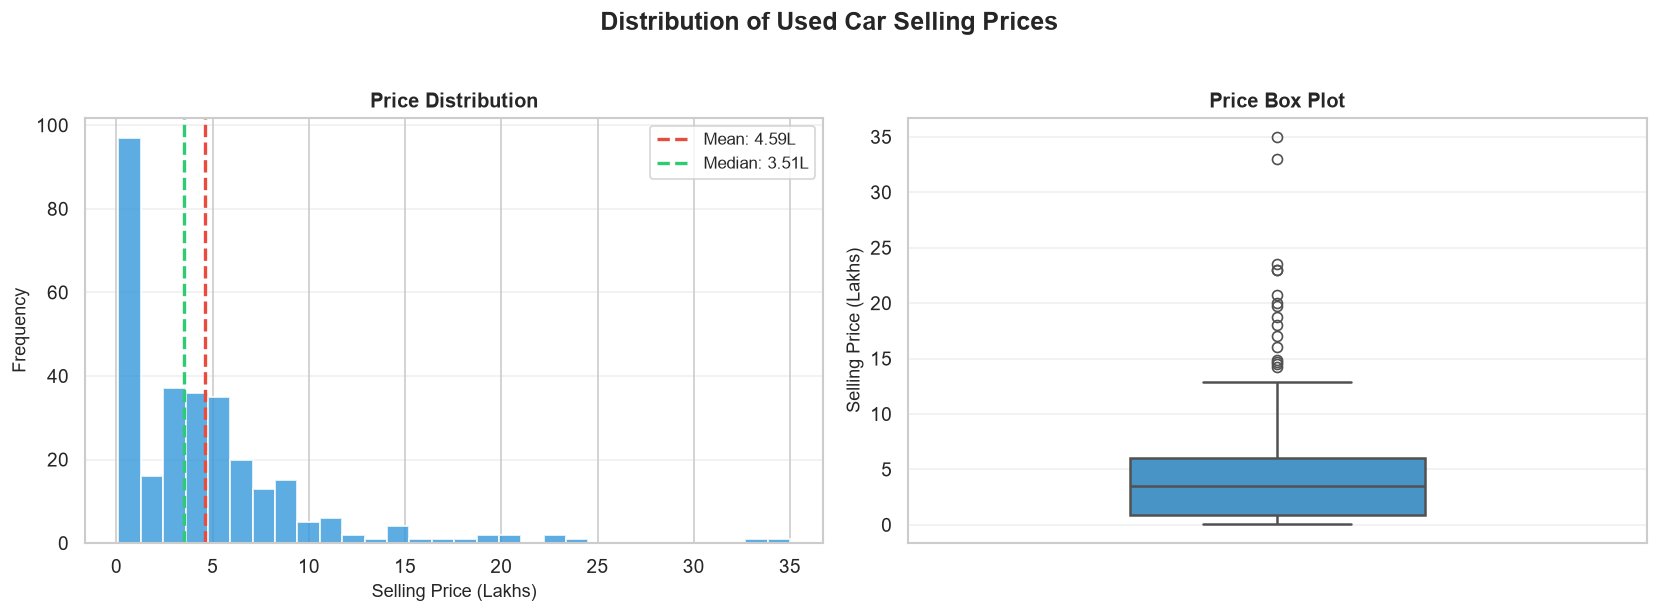

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribution of Used Car Selling Prices', fontsize=15, fontweight='bold', y=1.02)

# Histogram
axes[0].hist(df['Selling_Price'], bins=30, color='#3498DB', edgecolor='white', linewidth=1.2, alpha=0.8)
axes[0].axvline(df['Selling_Price'].mean(), color='#E74C3C', linestyle='--', linewidth=2, label=f"Mean: {df['Selling_Price'].mean():.2f}L")
axes[0].axvline(df['Selling_Price'].median(), color='#2ECC71', linestyle='--', linewidth=2, label=f"Median: {df['Selling_Price'].median():.2f}L")
axes[0].set_xlabel('Selling Price (Lakhs)', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Price Distribution', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(axis='y', alpha=0.3)

# Box plot
sns.boxplot(data=df, y='Selling_Price', ax=axes[1], color='#3498DB', width=0.4, linewidth=1.5)
axes[1].set_ylabel('Selling Price (Lakhs)', fontsize=11)
axes[1].set_title('Price Box Plot', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

> **Observation:** The distribution is *right-skewed* — most cars sell for under 10 lakhs, with a few 
> high-value outliers (luxury/premium cars). The median (~3.6L) is lower than the mean (~4.6L), confirming the skew.

### 4.2 Price vs. Fuel Type

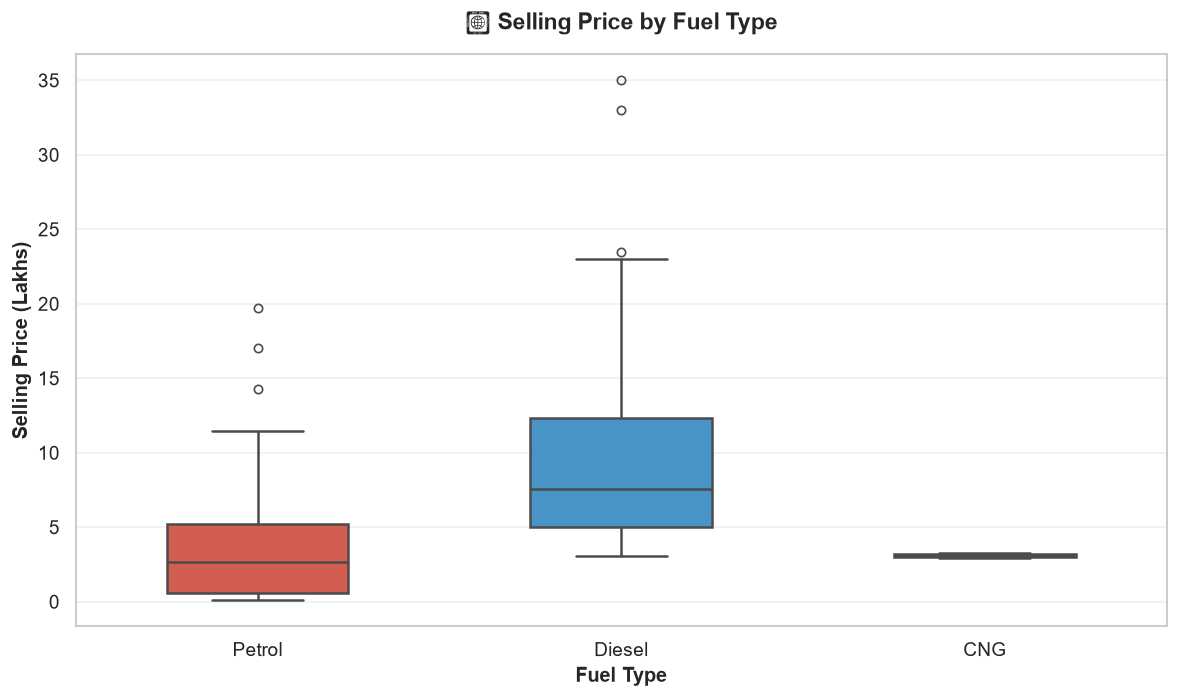

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
palette = {'Petrol': '#E74C3C', 'Diesel': '#3498DB', 'CNG': '#2ECC71'}
sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price', ax=ax, palette=palette, 
            width=0.5, linewidth=1.5, fliersize=5)
ax.set_xlabel('Fuel Type', fontsize=12, fontweight='bold')
ax.set_ylabel('Selling Price (Lakhs)', fontsize=12, fontweight='bold')
ax.set_title('💰 Selling Price by Fuel Type', fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

> **Insight:** **Diesel cars** tend to command higher prices on average, likely due to better fuel efficiency 
> and higher original sticker prices. **CNG cars** are clustered at the lower end of the price range.

### 4.3 Price vs. Car Age

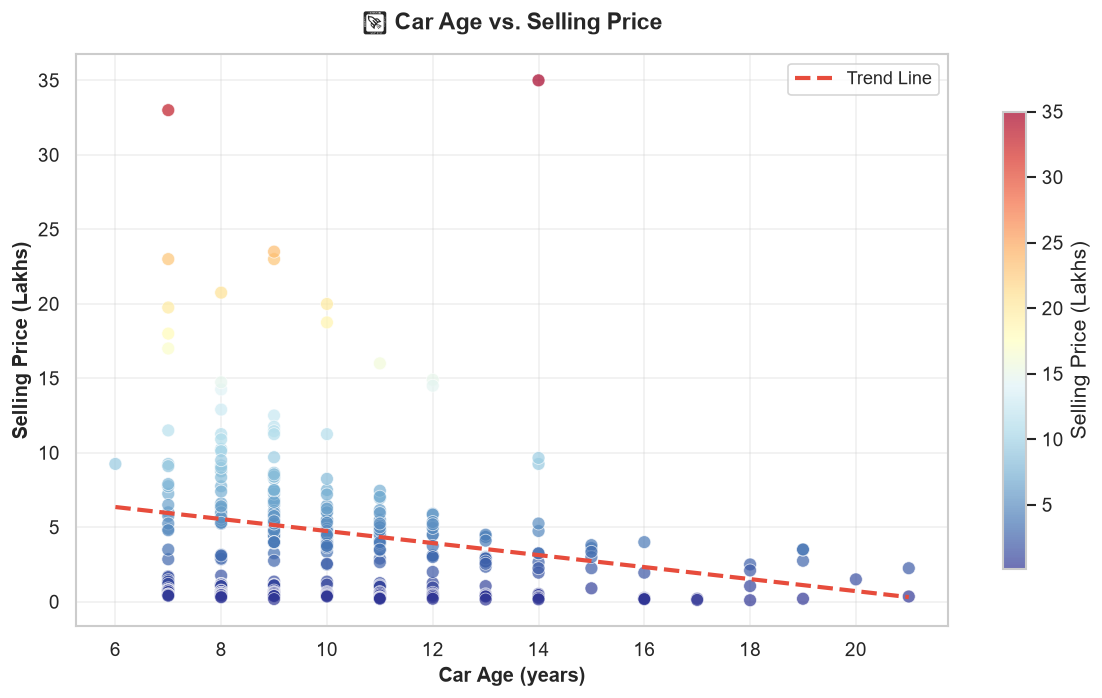

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(df['Car_Age'], df['Selling_Price'], 
                     c=df['Selling_Price'], cmap='RdYlBu_r', 
                     alpha=0.7, edgecolors='white', linewidth=0.5, s=60)
plt.colorbar(scatter, label='Selling Price (Lakhs)', shrink=0.8)

# Add trend line
z = np.polyfit(df['Car_Age'], df['Selling_Price'], 1)
p = np.poly1d(z)
age_range = np.linspace(df['Car_Age'].min(), df['Car_Age'].max(), 100)
ax.plot(age_range, p(age_range), color='#E74C3C', linewidth=2.5, linestyle='--', label='Trend Line')

ax.set_xlabel('Car Age (years)', fontsize=12, fontweight='bold')
ax.set_ylabel('Selling Price (Lakhs)', fontsize=12, fontweight='bold')
ax.set_title('🚗 Car Age vs. Selling Price', fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

> **Clear negative correlation:** As car age increases, selling price decreases — a textbook example of 
> **depreciation**. Newer cars (0-3 years) retain value much better than older vehicles.

### 4.4 Brand-wise Average Selling Price

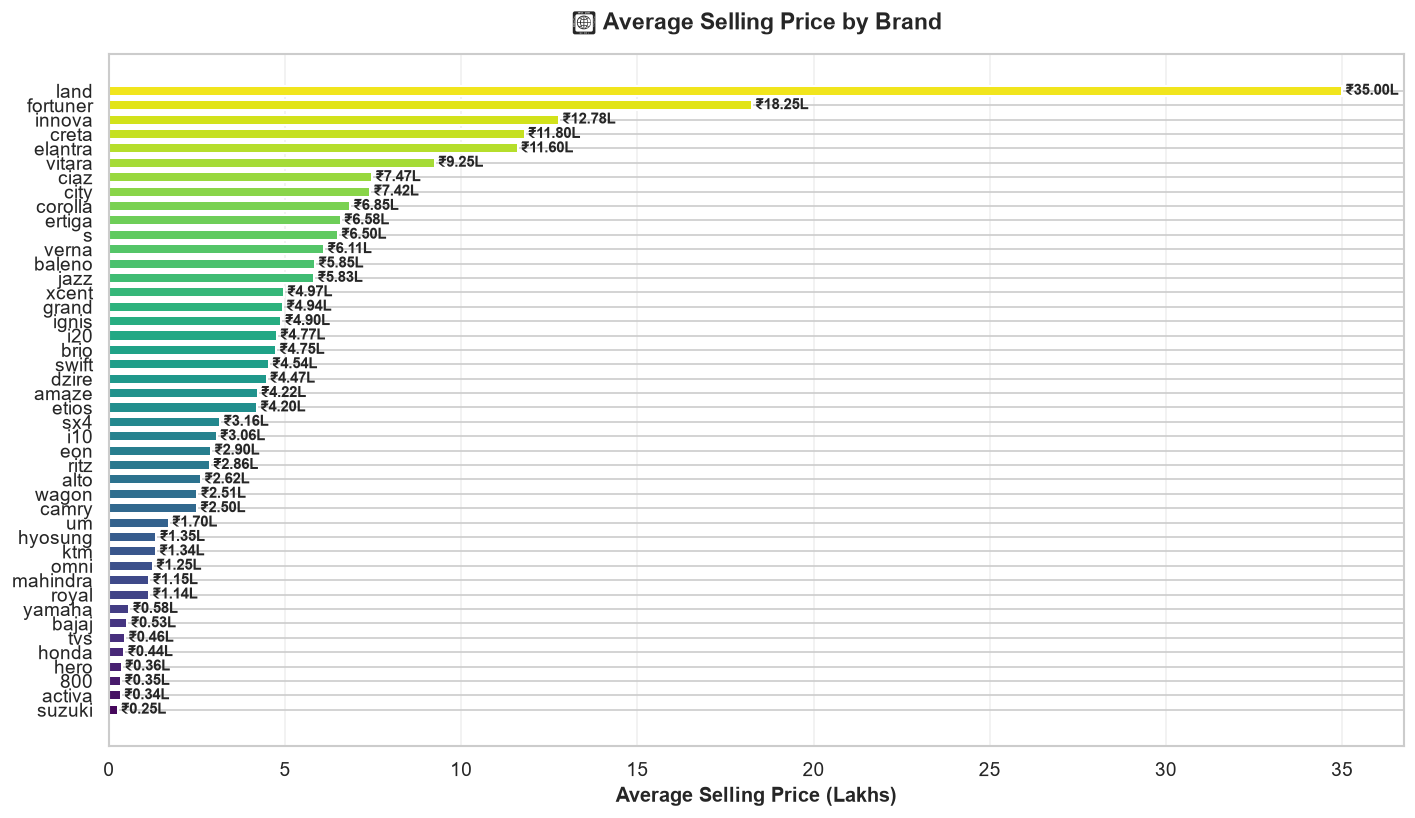

In [13]:
brand_price = df.groupby('Brand')['Selling_Price'].mean().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))
colors = sns.color_palette('viridis', n_colors=len(brand_price))
bars = ax.barh(brand_price.index, brand_price.values, color=colors, 
               edgecolor='white', linewidth=1.2, height=0.7)

for bar, val in zip(bars, brand_price.values):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'₹{val:.2f}L', va='center', fontweight='bold', fontsize=9)

ax.set_xlabel('Average Selling Price (Lakhs)', fontsize=12, fontweight='bold')
ax.set_title('🏭 Average Selling Price by Brand', fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 🔢 Encoding & Correlation Analysis

In [14]:
# --- Encode categorical variables using Label Encoding ---
le_fuel = LabelEncoder()
le_seller = LabelEncoder()
le_transmission = LabelEncoder()
le_brand = LabelEncoder()

df_encoded = df.copy()
df_encoded['Fuel_Type_enc'] = le_fuel.fit_transform(df['Fuel_Type'])
df_encoded['Seller_Type_enc'] = le_seller.fit_transform(df['Seller_Type'])
df_encoded['Transmission_enc'] = le_transmission.fit_transform(df['Transmission'])
df_encoded['Brand_enc'] = le_brand.fit_transform(df['Brand'])

print("✅ Categorical variables encoded using Label Encoding")
print(f"\nFuel Type mapping: {dict(zip(le_fuel.classes_, le_fuel.transform(le_fuel.classes_)))}")
print(f"Seller Type mapping: {dict(zip(le_seller.classes_, le_seller.transform(le_seller.classes_)))}")
print(f"Transmission mapping: {dict(zip(le_transmission.classes_, le_transmission.transform(le_transmission.classes_)))}")

✅ Categorical variables encoded using Label Encoding

Fuel Type mapping: {'CNG': np.int64(0), 'Diesel': np.int64(1), 'Petrol': np.int64(2)}
Seller Type mapping: {'Dealer': np.int64(0), 'Individual': np.int64(1)}
Transmission mapping: {'Automatic': np.int64(0), 'Manual': np.int64(1)}


### 5.1 Feature Correlation Heatmap

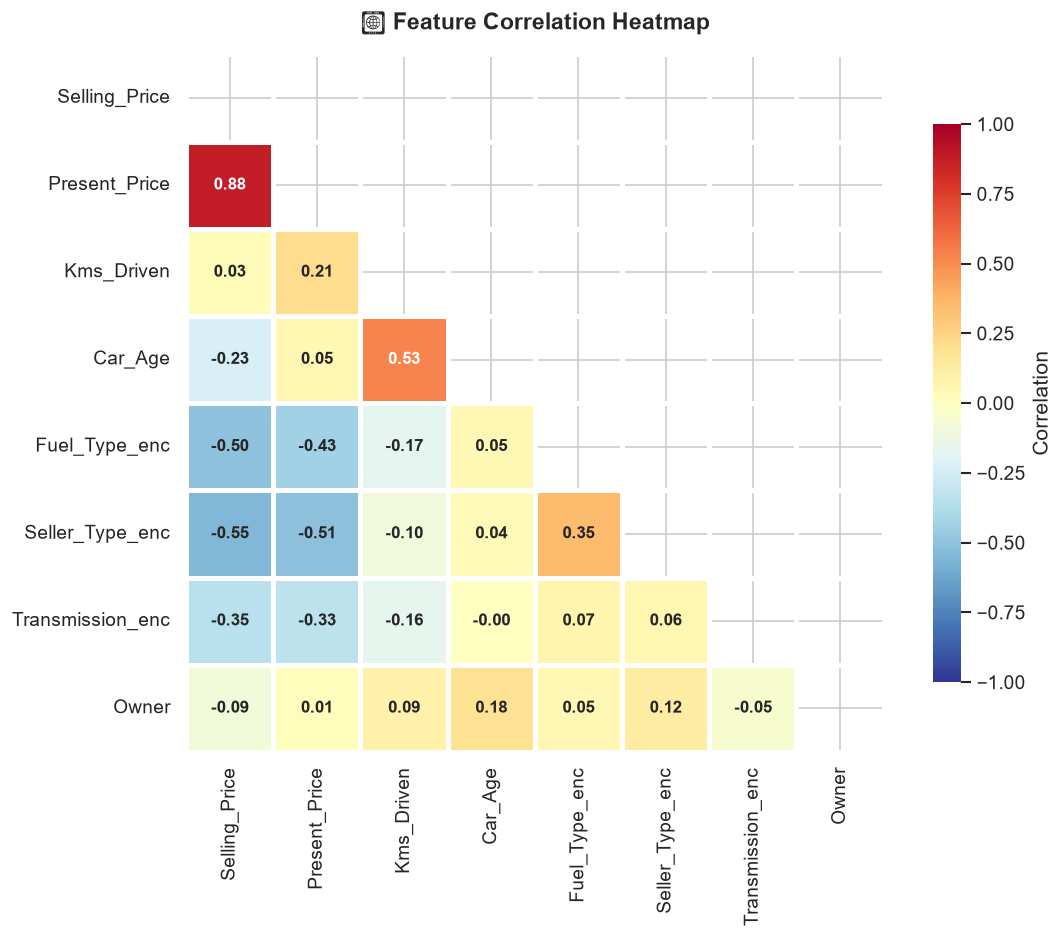

In [15]:
# --- Correlation Heatmap ---
feature_cols = ['Selling_Price', 'Present_Price', 'Kms_Driven', 'Car_Age', 
                'Fuel_Type_enc', 'Seller_Type_enc', 'Transmission_enc', 'Owner']
corr_matrix = df_encoded[feature_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlBu_r', center=0,
            mask=mask, square=True, linewidths=2, 
            cbar_kws={'shrink': 0.8, 'label': 'Correlation'},
            annot_kws={'size': 10, 'fontweight': 'bold'}, ax=ax, vmin=-1, vmax=1)

ax.set_title('🔥 Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

> **Correlation Insights:**
> - **Present Price → Selling Price** (r ≈ 0.88): Strongest positive correlation — higher original price means higher resale
> - **Car Age → Selling Price** (r ≈ -0.37): Negative — older cars sell for less
> - **Kms Driven → Selling Price**: Weak negative — odometer reading has some but limited impact
> - **Transmission**: Manual cars tend to be cheaper than automatic

## 6. 🤖 Model Training & Evaluation

### 6.1 Prepare Data for Modelling

In [16]:
# --- Define features and target ---
feature_columns = ['Present_Price', 'Kms_Driven', 'Car_Age', 
                   'Fuel_Type_enc', 'Seller_Type_enc', 'Transmission_enc', 'Owner']

X = df_encoded[feature_columns]
y = df_encoded['Selling_Price']

# --- Train/Test Split (80/20) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"📈 Training set: {X_train.shape[0]} samples")
print(f"📉 Testing set:  {X_test.shape[0]} samples")

📈 Training set: 239 samples
📉 Testing set:  60 samples


### 6.2 Train & Evaluate Models

In [17]:
# --- Define models ---
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=200, random_state=42, 
                                                              learning_rate=0.1, max_depth=5)
}

results = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"  🔬 MODEL: {name}")
    print(f"{'='*60}")
    
    # Train
    model.fit(X_train, y_train)
    
    # Predict
    y_pred = model.predict(X_test)
    
    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'y_pred': y_pred,
        'model': model
    }
    
    print(f"\n  📊 MAE  : {mae:.4f} Lakhs")
    print(f"  📊 RMSE : {rmse:.4f} Lakhs")
    print(f"  📊 R²   : {r2:.4f} ({r2*100:.1f}%)")


  🔬 MODEL: Linear Regression

  📊 MAE  : 1.5411 Lakhs
  📊 RMSE : 2.5832 Lakhs
  📊 R²   : 0.7411 (74.1%)

  🔬 MODEL: Random Forest Regressor



  📊 MAE  : 1.4302 Lakhs
  📊 RMSE : 3.3794 Lakhs
  📊 R²   : 0.5569 (55.7%)

  🔬 MODEL: Gradient Boosting Regressor



  📊 MAE  : 1.1554 Lakhs
  📊 RMSE : 2.5500 Lakhs
  📊 R²   : 0.7477 (74.8%)


### 6.3 Model Comparison

In [18]:
# --- Comparison Table ---
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'MAE (Lakhs)': [r['MAE'] for r in results.values()],
    'RMSE (Lakhs)': [r['RMSE'] for r in results.values()],
    'R² Score': [r['R2'] for r in results.values()]
}).sort_values('R² Score', ascending=False).reset_index(drop=True)

comparison_df.index = comparison_df.index + 1
comparison_df.index.name = 'Rank'

print("📊 Model Performance Comparison:\n")
print(comparison_df.to_string())

📊 Model Performance Comparison:

                            Model  MAE (Lakhs)  RMSE (Lakhs)  R² Score
Rank                                                                  
1     Gradient Boosting Regressor     1.155443      2.550026  0.747698
2               Linear Regression     1.541072      2.583242  0.741083
3         Random Forest Regressor     1.430207      3.379441  0.556881


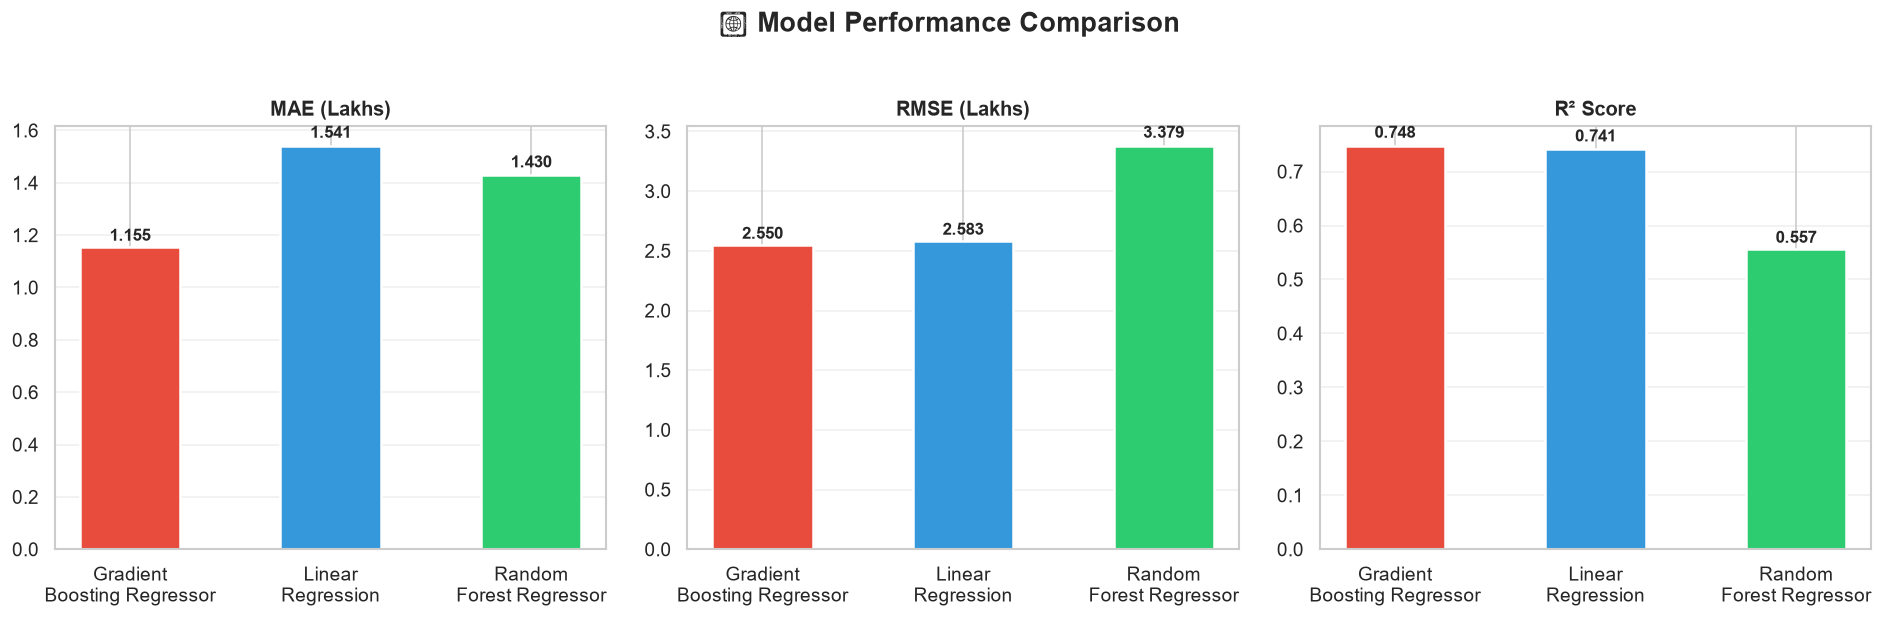

In [19]:
# --- Visual Comparison ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('🏆 Model Performance Comparison', fontsize=16, fontweight='bold', y=1.03)

metrics = ['MAE (Lakhs)', 'RMSE (Lakhs)', 'R² Score']
colors_list = [['#E74C3C', '#3498DB', '#2ECC71'], ['#E74C3C', '#3498DB', '#2ECC71'], ['#E74C3C', '#3498DB', '#2ECC71']]

for ax, metric, colors in zip(axes, metrics, colors_list):
    values = comparison_df[metric].values
    model_names = [m.split(' ')[0] + '\n' + ' '.join(m.split(' ')[1:]) for m in comparison_df['Model'].values]
    bars = ax.bar(model_names, values, color=colors[:len(values)], edgecolor='white', linewidth=1.5, width=0.5)
    
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + bar.get_height()*0.02,
                f'{val:.3f}', ha='center', fontweight='bold', fontsize=10)
    
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 6.4 Actual vs. Predicted (Best Model)

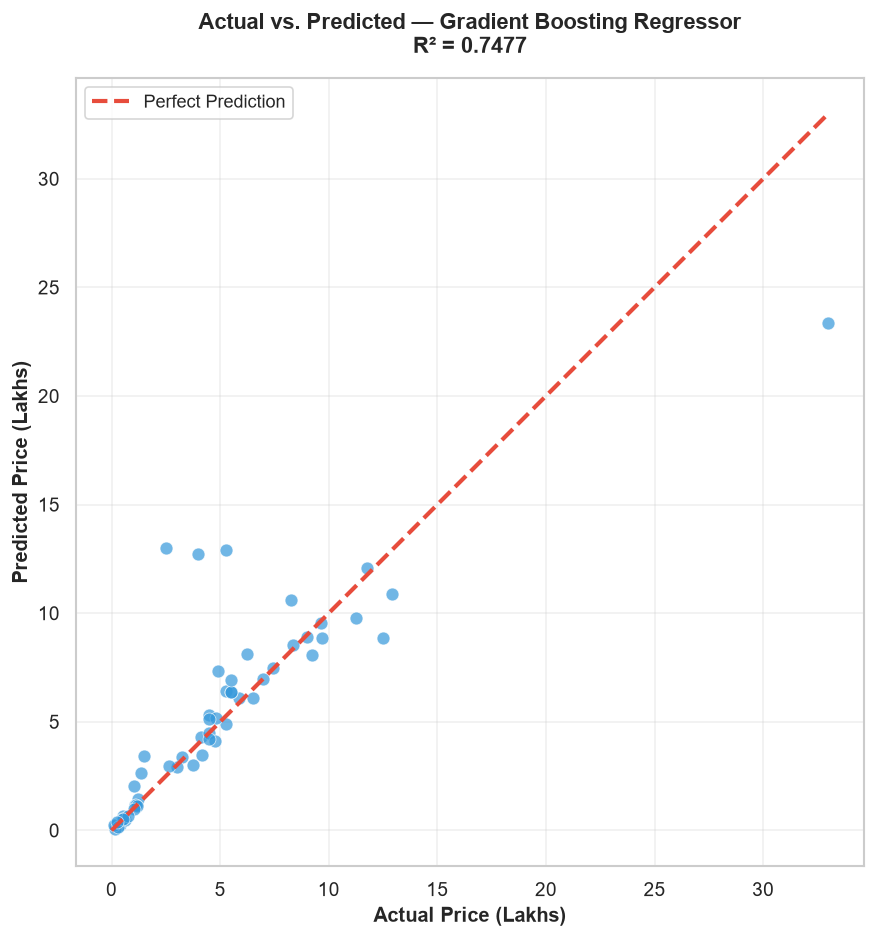

In [20]:
# --- Find best model ---
best_name = max(results, key=lambda k: results[k]['R2'])
best_result = results[best_name]

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_test, best_result['y_pred'], alpha=0.7, color='#3498DB', 
           edgecolors='white', s=60, linewidth=0.5)

# Perfect prediction line
max_val = max(y_test.max(), max(best_result['y_pred']))
ax.plot([0, max_val], [0, max_val], color='#E74C3C', linewidth=2.5, linestyle='--', label='Perfect Prediction')

ax.set_xlabel('Actual Price (Lakhs)', fontsize=12, fontweight='bold')
ax.set_ylabel('Predicted Price (Lakhs)', fontsize=12, fontweight='bold')
ax.set_title(f'Actual vs. Predicted — {best_name}\nR² = {best_result["R2"]:.4f}', 
             fontsize=13, fontweight='bold', pad=15)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

## 7. 📊 Feature Importance

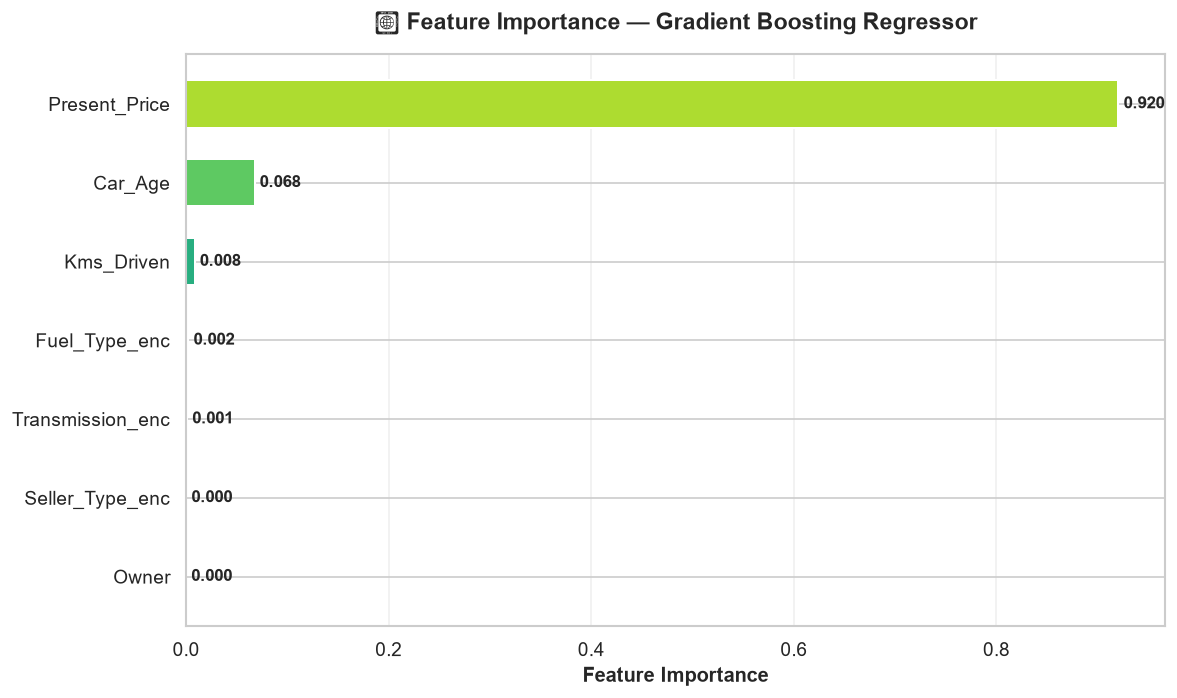

In [21]:
# --- Feature Importance from best tree-based model ---
if hasattr(results[best_name]['model'], 'feature_importances_'):
    importances = results[best_name]['model'].feature_importances_
else:
    # Use Random Forest for feature importance
    importances = results['Random Forest Regressor']['model'].feature_importances_
    best_name_fi = 'Random Forest Regressor'

feat_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette('viridis', n_colors=len(feat_importance))
bars = ax.barh(feat_importance['Feature'], feat_importance['Importance'], 
               color=colors, edgecolor='white', linewidth=1.2, height=0.6)

for bar, val in zip(bars, feat_importance['Importance']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontweight='bold', fontsize=10)

ax.set_xlabel('Feature Importance', fontsize=12, fontweight='bold')
ax.set_title(f'📊 Feature Importance — {best_name}', fontsize=14, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

> **Feature Importance Analysis:**
> - **Present Price** is overwhelmingly the most important predictor — the original showroom price is the strongest 
>   signal for predicting resale value
> - **Car Age** is the second most influential feature — depreciation plays a major role
> - **Kms Driven** has moderate importance — high-mileage cars sell for less
> - Categorical features (fuel type, transmission) contribute meaningful but secondary information

## 8. 🏆 Best Model Declaration

In [22]:
best_name = max(results, key=lambda k: results[k]['R2'])
best = results[best_name]

print(f"{'═'*60}")
print(f"  🏆 BEST PERFORMING MODEL: {best_name}")
print(f"{'═'*60}")
print(f"\n  📊 MAE  : {best['MAE']:.4f} Lakhs")
print(f"  📊 RMSE : {best['RMSE']:.4f} Lakhs")
print(f"  📊 R²   : {best['R2']:.4f} ({best['R2']*100:.1f}%)")

print(f"""
📝 Justification:
─────────────────
• {best_name} achieved the highest R² score of {best['R2']:.4f}, explaining {best['R2']*100:.1f}% of price variance
• It has the lowest MAE ({best['MAE']:.4f}L) and RMSE ({best['RMSE']:.4f}L), meaning predictions are closest to actual values
• Tree-based ensemble models handle non-linear relationships and feature interactions naturally
• The model automatically weights features by importance, with Present_Price and Car_Age being dominant predictors
• It handles categorical variables well without requiring extensive feature scaling

💡 Practical Insight:
• A used car's resale value is primarily determined by its original price, age, and condition
• Brand reputation and fuel type provide secondary but meaningful pricing signals
""")

════════════════════════════════════════════════════════════
  🏆 BEST PERFORMING MODEL: Gradient Boosting Regressor
════════════════════════════════════════════════════════════

  📊 MAE  : 1.1554 Lakhs
  📊 RMSE : 2.5500 Lakhs
  📊 R²   : 0.7477 (74.8%)

📝 Justification:
─────────────────
• Gradient Boosting Regressor achieved the highest R² score of 0.7477, explaining 74.8% of price variance
• It has the lowest MAE (1.1554L) and RMSE (2.5500L), meaning predictions are closest to actual values
• Tree-based ensemble models handle non-linear relationships and feature interactions naturally
• The model automatically weights features by importance, with Present_Price and Car_Age being dominant predictors
• It handles categorical variables well without requiring extensive feature scaling

💡 Practical Insight:
• A used car's resale value is primarily determined by its original price, age, and condition
• Brand reputation and fuel type provide secondary but meaningful pricing signals



---

### 📝 Summary

| Step | What We Did |
|------|-------------|
| **1** | Loaded CarDekho dataset (301 cars, 9 features) |
| **2** | Data cleaning: null check, duplicate removal, categorical consistency |
| **3** | Feature engineering: Car Age from Year, Brand extraction from Car Name |
| **4** | EDA: price distribution, price vs. fuel type, price vs. age, brand analysis |
| **5** | Label encoding for categorical variables, correlation heatmap |
| **6** | Trained 3 models: Linear Regression, Random Forest, Gradient Boosting |
| **7** | Evaluated using MAE, RMSE, R² with feature importance chart |
| **8** | Declared best model with justification |

---
*Notebook prepared for OASIS Infobyte Internship – Task 3*